# Optuna Hyperparameter Search — LSTM (PyTorch)

Grid-search the LSTM training hyperparameters that give the **lowest validation MSE**
per stock, using Optuna's `GridSampler` over **27 combinations** (3 lr × 3 batch × 3 epochs).

> **This notebook only *reports* MSE** — it does not auto-apply anything. Read the tables,
> pick the values you want, and set them in `BL_LSTM_Portfolio.ipynb` / `src/constants.py` by hand.

**Adapted from `Optuna_Hyperparameter_Search_Plan.md`.** The plan was written for
TensorFlow/Keras + `data/processed/*.npz`; this repo is PyTorch, so the notebook reuses the
existing `src/` modules instead:

| Plan (Keras)                         | Here (this repo)                                   |
|--------------------------------------|----------------------------------------------------|
| `build_lstm()` Keras `Sequential`    | `src.lstm_model.LSTMRegressor` (4×60, Arch B)      |
| `model.fit(...)` + Keras callbacks   | `src.lstm_model._train_one` (early-stop + LR plateau, returns best val MSE) |
| load `data/processed/{t}_train.npz`  | `fetch_data.fetch` → `build_stock_dataset` (in-memory, cache-backed) |
| `TFKerasPruningCallback`             | omitted — no per-epoch hook in `_train_one`; GridSampler still runs all 27 |
| `results/optuna_mse_map.png`         | `output/optuna_mse_map.png` (repo convention)      |

Open this notebook **from the `bl_lstm_views/` folder** so `from src import …` resolves.

In [1]:
import os, itertools, warnings
import numpy as np
import matplotlib.pyplot as plt
import torch
import optuna

from src import constants as C
from src import fetch_data
from src.preprocessing import build_stock_dataset
from src.lstm_model import _train_one, get_device, _empty_cache

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)   # silence per-trial optuna noise

TICKERS = ["LLY", "CRWD", "RBRK"]
DEVICE  = get_device(os.environ.get("OPTUNA_DEVICE", "auto"))

SEARCH_SPACE = {
    "learning_rate":        [1e-4, 5e-4, 1e-3, 5e-3],
    "batch_size":           [32, 64, 128, 256],
    "early_stop_patience":  [10, 20, 30],
    "lr_plateau_patience":  [5, 10, 15],
}
# epochs ไม่ tune — ตั้งสูงไว้ ปล่อยให้ early stopping หยุดเอง
FIXED_EPOCHS = 600
N_TRIALS = int(np.prod([len(v) for v in SEARCH_SPACE.values()]))   # = 108 combinations

print(f"device={DEVICE.type}  fixed_epochs={FIXED_EPOCHS}  trials/stock={N_TRIALS}")

/Users/doyinratnavardhana/Quantitative-modeler/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device=mps  fixed_epochs=600  trials/stock=144


## Step 1 — Load data

No `data/processed/*.npz` in this repo — datasets are built in-memory exactly like the main
pipeline: `fetch_data.fetch` (cache-backed) → `build_stock_dataset` (8 indicators, train-only
MinMax, 30-day windows, 5-day-ahead targets). A ticker whose data won't fetch or is too short
to window is **skipped**, and the search continues on the rest.

In [2]:
raw = fetch_data.fetch(TICKERS, with_market_caps=False)
datasets = {}
for t, df in raw["prices"].items():
    try:
        sd = build_stock_dataset(t, df)
        w = sd.windows
        datasets[t] = {
            "X_train": w["X"][w["train"]], "Yf_train": w["Y"][w["train"]],
            "X_val":   w["X"][w["val"]],   "Yf_val":   w["Y"][w["val"]],
        }
        print(f"✅ {t:<5} loaded — train: {datasets[t]['X_train'].shape}, "
              f"val: {datasets[t]['X_val'].shape}")
    except Exception as e:
        print(f"⚠️  {t}: skipped ({e})")

TICKERS = list(datasets.keys())   # reconcile to what actually built
assert TICKERS, "no usable tickers"


  ↗  Fetching ['LLY', 'CRWD', 'RBRK']  (2010-01-01 → 2026-06-24)
  ✅  LLY: 4142 daily bars
  ✅  CRWD: 1767 daily bars
  ✅  RBRK: 541 daily bars
✅ LLY   loaded — train: (2854, 30, 8), val: (816, 30, 8)
✅ CRWD  loaded — train: (1192, 30, 8), val: (340, 30, 8)
✅ RBRK  loaded — train: (333, 30, 8), val: (96, 30, 8)


## Step 2 — Trainer

The plan's `build_lstm()` + Keras `model.fit` are replaced by `src.lstm_model._train_one`,
which builds the same 4×60 multi-output `LSTMRegressor` (Architecture B) and trains it with
**val-driven early stopping + ReduceLROnPlateau**, returning the best validation MSE — exactly
the quantity Optuna minimises. (`epochs` is the *cap*; early-stopping may end a trial sooner.)

In [3]:
def trial_val_mse(ticker, lr, bs, es_patience, lr_patience):
    """Train one LSTM with the given hyperparameters; return its best validation MSE."""
    d = datasets[ticker]
    torch.manual_seed(42)   # same init across trials → fair hyperparameter comparison
    model, best_val = _train_one(
        d["X_train"], d["Yf_train"], d["X_val"], d["Yf_val"],
        epochs=FIXED_EPOCHS, lr=lr, batch=bs, device=DEVICE, ticker=ticker, log_every=0,
        patience=es_patience, lr_plateau_patience=lr_patience,
    )
    del model
    _empty_cache(DEVICE)
    return float(best_val)


## Step 3 — Optuna objective

`make_objective(ticker)` closes over that stock's dataset (so one study = one stock) and asks
Optuna for an `(lr, batch, epochs)` combination from the search space, returning the resulting
validation MSE.

In [4]:
def make_objective(ticker):
    def objective(trial):
        lr          = trial.suggest_categorical("learning_rate",       SEARCH_SPACE["learning_rate"])
        bs          = trial.suggest_categorical("batch_size",          SEARCH_SPACE["batch_size"])
        es_patience = trial.suggest_categorical("early_stop_patience", SEARCH_SPACE["early_stop_patience"])
        lr_patience = trial.suggest_categorical("lr_plateau_patience", SEARCH_SPACE["lr_plateau_patience"])
        return trial_val_mse(ticker, lr, bs, es_patience, lr_patience)
    return objective


## Step 4 — Run the search

One `GridSampler` study per stock (the small 27-point space → grid search beats TPE here),
`n_trials = 27` covers every combination. A per-trial callback prints each result as it lands.

In [5]:
def _trial_summary_callback(ticker):
    def callback(study, trial):
        if trial.value is None:
            return
        best = "  ⭐ best!" if trial.value <= study.best_value + 1e-12 else ""
        p = trial.params
        print(f"  Trial {trial.number + 1:>2}/{N_TRIALS} | "
              f"lr={p['learning_rate']:.4f}, bs={p['batch_size']:>3}, "
              f"es={p['early_stop_patience']:>2}, lr_p={p['lr_plateau_patience']:>2} "
              f"→ MSE={trial.value:.4f}{best}")
    return callback


all_studies = {}
all_best_params = {}

for ticker in TICKERS:
    print("\n" + "=" * 55)
    print(f"🔍 Searching hyperparameters: {ticker}  ({N_TRIALS} combinations)")
    print("=" * 55)
    study = optuna.create_study(
        direction="minimize",
        study_name=f"lstm_{ticker}",
        sampler=optuna.samplers.GridSampler(SEARCH_SPACE),
    )
    study.optimize(make_objective(ticker), n_trials=N_TRIALS,
                   callbacks=[_trial_summary_callback(ticker)])

    best = dict(study.best_params)
    best["val_mse"] = study.best_value
    all_studies[ticker] = study
    all_best_params[ticker] = best
    print(f"\n✅ [{ticker}] best → lr={best['learning_rate']}, "
          f"batch={best['batch_size']}, " \
          f"es_patience={best['early_stop_patience']}, lr_patience={best['lr_plateau_patience']}, "
          f"val MSE={best['val_mse']:.4f}")



🔍 Searching hyperparameters: LLY  (144 combinations)
      [LLY] early stop at epoch 31 (best val 0.3858)
  Trial  1/144 | lr=0.0010, bs= 32, es=10, lr_p=10 → MSE=0.3858  ⭐ best!
      [LLY] early stop at epoch 91 (best val 0.3665)
  Trial  2/144 | lr=0.0005, bs=128, es=20, lr_p=15 → MSE=0.3665  ⭐ best!
      [LLY] early stop at epoch 233 (best val 0.4051)
  Trial  3/144 | lr=0.0001, bs=128, es=30, lr_p=10 → MSE=0.4051
      [LLY] early stop at epoch 120 (best val 0.4349)
  Trial  4/144 | lr=0.0001, bs= 32, es=30, lr_p=15 → MSE=0.4349
      [LLY] early stop at epoch 198 (best val 0.4319)
  Trial  5/144 | lr=0.0001, bs=256, es=10, lr_p=15 → MSE=0.4319
      [LLY] early stop at epoch 89 (best val 0.3786)
  Trial  6/144 | lr=0.0010, bs=256, es=20, lr_p=15 → MSE=0.3786
      [LLY] early stop at epoch 47 (best val 0.3232)
  Trial  7/144 | lr=0.0050, bs= 64, es=20, lr_p=15 → MSE=0.3232  ⭐ best!
      [LLY] early stop at epoch 39 (best val 0.3387)
  Trial  8/144 | lr=0.0050, bs= 32, es=20, l

## Step 5 — MSE results

Every combination, sorted best→worst per stock, plus a heatmap (lr × batch, colour = MSE,
marker size = epochs). Use these to choose values by hand — nothing here is applied automatically.


📊 LLY — val MSE, every combination (best → worst)
    #        LR  Batch    ES  LR_P    Val MSE
  ----------------------------------------------------
  ⭐ 1.    0.0050     64    20    15     0.3232
     2.    0.0050     64    30    15     0.3232
     3.    0.0050     32    20    10     0.3387
     4.    0.0050     32    30     5     0.3387
     5.    0.0050     32    10    10     0.3387
     6.    0.0050     32    10    15     0.3387
     7.    0.0050     32    30    10     0.3387
     8.    0.0050     32    30    15     0.3387
     9.    0.0050     32    20    15     0.3387
    10.    0.0050     32    20     5     0.3387
    11.    0.0050     32    10     5     0.3387
    12.    0.0050     64    20    10     0.3540
    13.    0.0050     64    30    10     0.3540
    14.    0.0050    256    20    15     0.3577
    15.    0.0050    256    30    10     0.3577
    16.    0.0050    256    10    10     0.3577
    17.    0.0050    256    10    15     0.3577
    18.    0.0050    256    20   

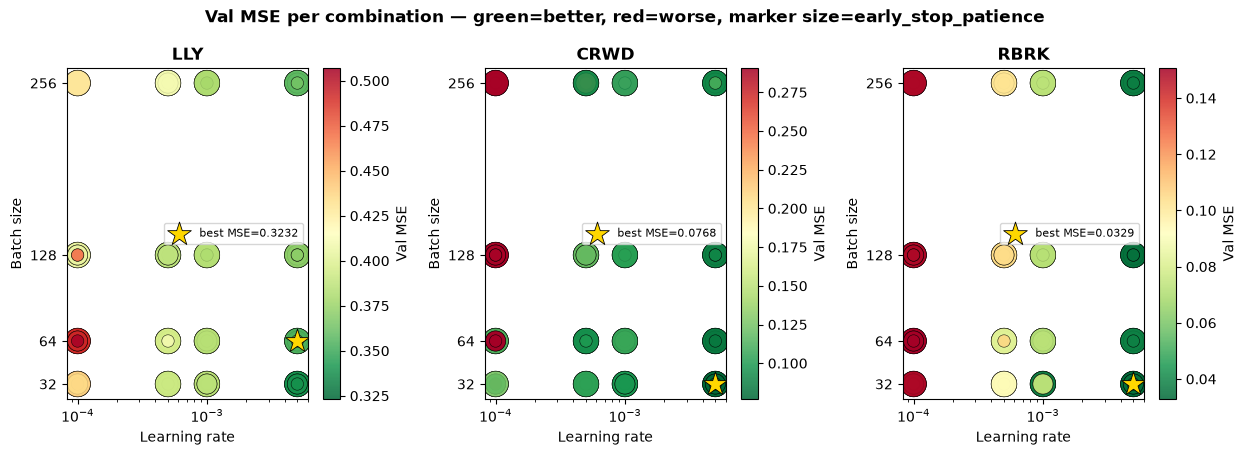


📈 saved heatmap → output/optuna_mse_map.png

ℹ️  Reporting only — copy the values you want into src/constants.py / the main notebook.


In [6]:
for ticker in TICKERS:
    trials = [t for t in all_studies[ticker].trials if t.value is not None]
    trials.sort(key=lambda t: t.value)
    print("\n" + "=" * 60)
    print(f"📊 {ticker} — val MSE, every combination (best → worst)")
    print("=" * 60)
    print(f"  {'#':>3}  {'LR':>8}  {'Batch':>5}  {'ES':>4}  {'LR_P':>4}  {'Val MSE':>9}")
    print("  " + "-" * 52)
    for rank, t in enumerate(trials, 1):
        star = "⭐" if rank == 1 else "  "
        p = t.params
        print(f"  {star}{rank:>2}.  {p['learning_rate']:>8.4f}  {p['batch_size']:>5}  "
              f"{p['early_stop_patience']:>4}  {p['lr_plateau_patience']:>4}  {t.value:>9.4f}")

# ── heatmap: lr (log x) × batch (y), colour = MSE, size = early_stop_patience ──
n = len(TICKERS)
fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 4.6), squeeze=False)
axes = axes[0]
all_esp = SEARCH_SPACE["early_stop_patience"]
esp_lo, esp_hi = min(all_esp), max(all_esp)

def _msize(esp):
    f = 0.0 if esp_hi == esp_lo else (esp - esp_lo) / (esp_hi - esp_lo)
    return 80 + 260 * f

for i, ticker in enumerate(TICKERS):
    trials = [t for t in all_studies[ticker].trials if t.value is not None]
    lrs = [t.params["learning_rate"] for t in trials]
    bss = [t.params["batch_size"] for t in trials]
    esp = [t.params["early_stop_patience"] for t in trials]
    mse = [t.value for t in trials]
    ax = axes[i]
    sc = ax.scatter(lrs, bss, c=mse, s=[_msize(e) for e in esp],
                    cmap="RdYlGn_r", alpha=0.85, edgecolors="k", linewidths=0.4)
    plt.colorbar(sc, ax=ax, label="Val MSE")
    ax.set_xscale("log"); ax.set_xlabel("Learning rate"); ax.set_ylabel("Batch size")
    ax.set_yticks(SEARCH_SPACE["batch_size"]); ax.set_title(ticker, fontweight="bold")
    b = min(trials, key=lambda t: t.value)
    ax.scatter(b.params["learning_rate"], b.params["batch_size"], marker="*",
               s=320, color="gold", edgecolors="k", linewidths=0.6, zorder=5,
               label=f"best MSE={b.value:.4f}")
    ax.legend(fontsize=8, loc="best")

plt.suptitle("Val MSE per combination — green=better, red=worse, marker size=early_stop_patience",
             fontsize=12, fontweight="bold")
plt.tight_layout()
out_png = os.path.join(C.OUTPUT_DIR, "optuna_mse_map.png")
os.makedirs(C.OUTPUT_DIR, exist_ok=True)
plt.savefig(out_png, dpi=150, bbox_inches="tight")
plt.show()
print(f"\n📈 saved heatmap → {os.path.relpath(out_png, C.ROOT_DIR)}")
print("\nℹ️  Reporting only — copy the values you want into src/constants.py / the main notebook.")
